# Netflix Content Pattern Analysis

**Name:** Dakshata S P  
**Roll no:** 25BAD133

## Week 7 – Dimensionality Reduction using PCA

In this week, I am working on preparing the selected Netflix features for PCA. I will create a numerical feature table, handle missing values in the PCA input, encode the selected categories, standardize the features and apply PCA. I will also check the explained variance and save the PCA output.

I have used the cleaned Netflix dataset prepared in the earlier weeks. The code and observations below are for this week's task only.

## 1. Importing Required Libraries

I use **Pandas and NumPy** to prepare the dataset and perform numerical operations. **Matplotlib and Seaborn** are used to create charts. From Scikit-learn, I use `SimpleImputer` to fill missing values, `StandardScaler` to put features on a comparable scale, and `PCA` to reduce the number of dimensions.

These libraries are needed because PCA works with numerical data and the results are easier to understand when supported by correlation and explained-variance charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 2. Loading the Dataset Prepared in Week 6

I load the feature-engineered Netflix catalogue created in Week 6. If that file is not available, the notebook tries the cleaned dataset instead. This keeps the work connected to the earlier cleaning and feature-engineering steps.

The dataset contains catalogue information about titles. It does not contain individual users' viewing histories, so the analysis describes patterns in the catalogue rather than actual viewing behaviour.

In [2]:
possible_paths = [
    Path("Dataset/netflix_feature_engineered.csv"),
    Path("netflix_feature_engineered.csv"),
    Path("../Dataset/netflix_feature_engineered.csv"),
    Path("netflix_cleaned.csv"),
    Path("Dataset/netflix_cleaned.csv"),
    Path("../Dataset/netflix_cleaned.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find the Week 6 feature-engineered file or netflix_cleaned.csv. "
        "Update possible_paths to match your project folders."
    )

df = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Dataset shape:", df.shape)
display(df.head())

Loaded: netflix_cleaned.csv
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. Preparing PCA Features

PCA can only work with numerical input, so I prepare these catalogue features:

- `release_year`: the year the title was released.
- `movie_duration_min`: movie runtime in minutes.
- `tv_seasons`: number of seasons for TV Shows.

Movie runtime and TV season count are kept in separate columns because they measure different things. A movie's duration is not comparable to a TV Show's season count. Missing values are expected for the feature that does not apply to a title type.

In [3]:
# Recreate duration-derived fields if they are not already present.
if "movie_duration_min" not in df.columns or "tv_seasons" not in df.columns:
    duration_value = pd.to_numeric(
        df["duration"].astype("string").str.extract(r"(\d+)")[0],
        errors="coerce"
    )
    df["movie_duration_min"] = duration_value.where(df["type"].eq("Movie"))
    df["tv_seasons"] = duration_value.where(df["type"].eq("TV Show"))

numeric_features = ["release_year", "movie_duration_min", "tv_seasons"]
X_numeric = df[numeric_features].copy()

display(X_numeric.describe())

,release_year,movie_duration_min,tv_seasons
count,8807.000000,6128.0,2676.0
mean,2014.180198,99.577187,1.764948
std,8.819312,28.290593,1.582752
min,1925.000000,3.0,1.0
25%,2013.000000,87.0,1.0
50%,2017.000000,98.0,1.0
75%,2019.000000,114.0,2.0
max,2021.000000,312.0,17.0


## 4. Encoding Categorical Features

I use **One-Hot Encoding** with `pandas.get_dummies()` for the `type` and `rating` columns. Each category becomes a separate column containing `1` when the title belongs to that category and `0` otherwise. For example, the `Movie` and `TV Show` categories become separate binary columns.

For `listed_in`, I use **Multi-Hot Encoding** (also called multi-label binary encoding). A title can have several genres, so each selected genre gets its own column. A value of `1` means the title is listed in that genre, and `0` means it is not.

These methods are suitable because the categories do not have a natural numerical order. Label Encoding could assign numbers that might incorrectly suggest that one category is greater than another.

In [4]:
# One-hot encode content type and rating.
X_categorical = pd.get_dummies(
    df[["type", "rating"]].fillna("Unknown"),
    columns=["type", "rating"],
    dtype=int
)

# Identify the 10 most frequent genre labels.
genre_lists = (
    df["listed_in"].fillna("")
    .apply(lambda value: [g.strip() for g in value.split(",") if g.strip()])
)

genre_counts = pd.Series(
    [genre for genres in genre_lists for genre in genres]
).value_counts()

top_genres = genre_counts.head(10).index.tolist()
print("Selected genres:", top_genres)

# Create one binary column for each selected genre.
X_genres = pd.DataFrame(index=df.index)

for genre in top_genres:
    X_genres[f"genre_{genre}"] = genre_lists.apply(
        lambda genres: int(genre in genres)
    )

display(X_categorical.head())
display(X_genres.head())

Selected genres: ['International Movies', 'Dramas', 'Comedies', 'International TV Shows', 'Documentaries', 'Action & Adventure', 'TV Dramas', 'Independent Movies', 'Children & Family Movies', 'Romantic Movies']


,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,1,0,0,1,0,0,0
2,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0


## 5. Combining the PCA Input Features

I combine the numerical features, one-hot encoded content type and rating columns, and multi-hot encoded genre columns into one feature matrix.

Some values are missing because movie runtime applies to movies while season count applies to TV Shows. I use **median imputation** to fill missing numeric values in the PCA working matrix. The median is less affected by unusually high or low values than the mean.

This imputation is only for preparing the PCA input; it does not mean that the original Netflix dataset has been changed.

In [5]:
X = pd.concat(
    [X_numeric, X_categorical, X_genres],
    axis=1
)

# Ensure all PCA input columns are numeric.
X = X.apply(pd.to_numeric, errors="coerce")

imputer = SimpleImputer(strategy="median")
X_imputed_array = imputer.fit_transform(X)

X_imputed = pd.DataFrame(
    X_imputed_array,
    columns=X.columns,
    index=X.index
)

print("PCA input shape before imputation:", X.shape)
print("PCA input shape after imputation:", X_imputed.shape)
print("Missing values remaining:", int(X_imputed.isna().sum().sum()))

PCA input shape before imputation: (8807, 32)
PCA input shape after imputation: (8807, 32)
Missing values remaining: 0


## 6. Correlation Matrix and Feature Review

I calculate a **Pearson correlation matrix** to check how strongly pairs of numerical/binary features are related. Correlation values range from -1 to +1: values close to +1 indicate a strong positive relationship, values close to -1 indicate a strong negative relationship, and values near 0 indicate a weak linear relationship.

**Why use a heatmap?** A heatmap displays the full correlation matrix in one view. The colour intensity makes it easier to spot groups of features that are strongly related, which is useful before selecting features for PCA.

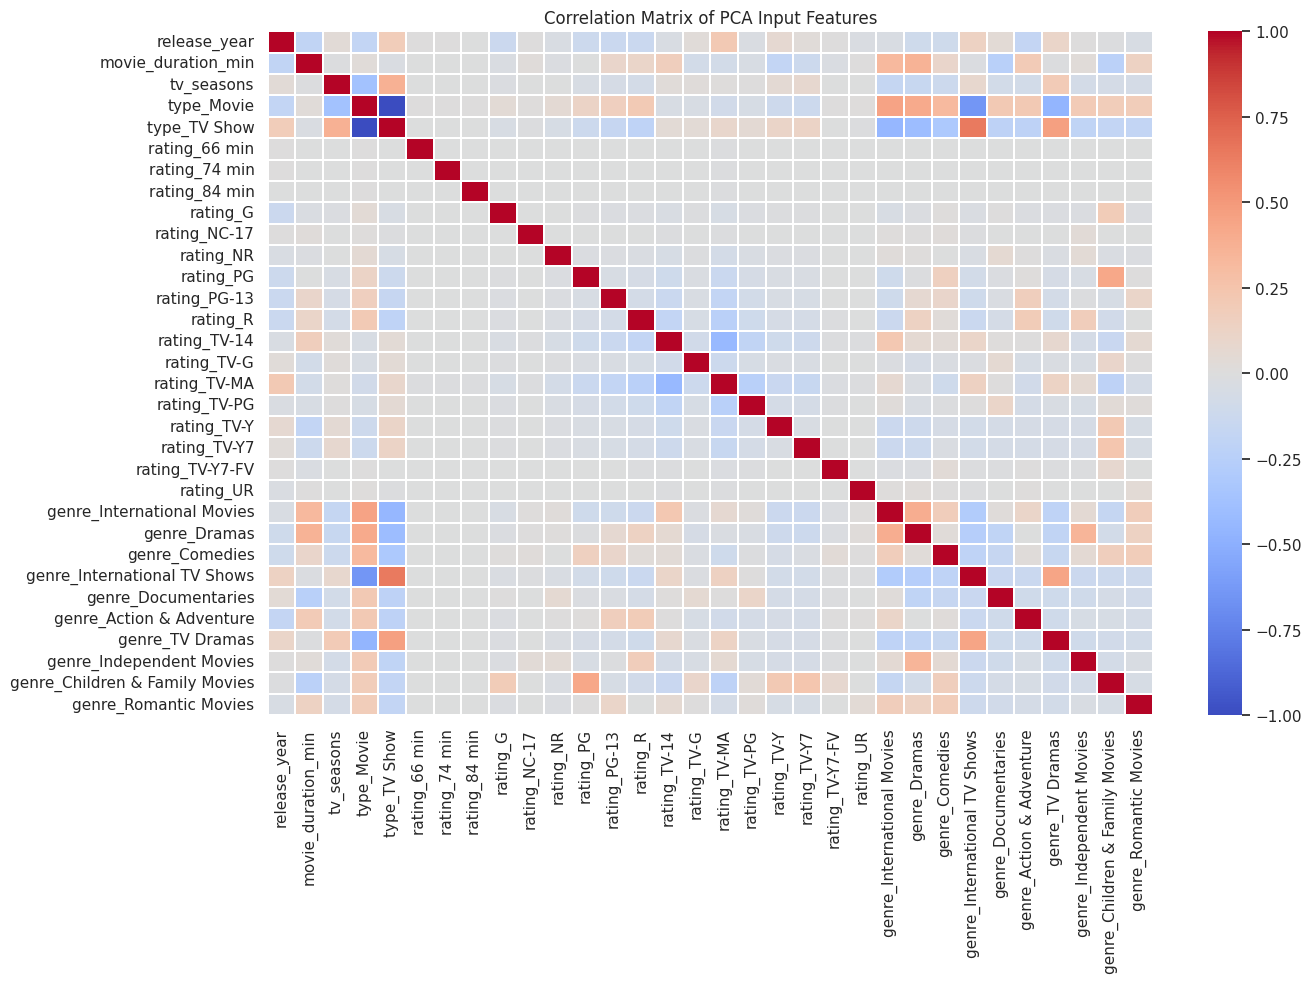

Highly correlated feature pairs (absolute correlation > 0.90):
type_TV Show and type_Movie: 1.000


In [6]:
correlation_matrix = X_imputed.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)
plt.title("Correlation Matrix of PCA Input Features")
plt.tight_layout()
plt.show()

threshold = 0.90
upper_triangle = correlation_matrix.abs().where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = [
    (col, row, upper_triangle.loc[row, col])
    for col in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, col])
    and upper_triangle.loc[row, col] > threshold
]

print("Highly correlated feature pairs (absolute correlation > 0.90):")
for feature_1, feature_2, corr_value in high_corr_pairs:
    print(f"{feature_1} and {feature_2}: {corr_value:.3f}")

### 6.1 Selecting Features for PCA

I use a correlation threshold of **0.95** to flag pairs of features with very high absolute correlation. When two features cross this threshold, one is removed from the PCA input to reduce repeated information.

This is a simple correlation-based feature-selection step. It does not prove that a feature is unimportant in every context; it only reduces highly similar inputs before PCA.

In [7]:
threshold = 0.95
upper_triangle = correlation_matrix.abs().where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

features_to_drop = [
    column
    for column in upper_triangle.columns
    if (upper_triangle[column] > threshold).any()
]

selected_features = [
    column for column in X_imputed.columns
    if column not in features_to_drop
]

X_selected = X_imputed[selected_features].copy()

print("Features removed due to high correlation:")
print(features_to_drop if features_to_drop else "None")

print("\\nNumber of features before selection:", X_imputed.shape[1])
print("Number of features after selection:", X_selected.shape[1])
display(X_selected.head())


Features removed due to high correlation:
['type_TV Show']
\nNumber of features before selection: 32
Number of features after selection: 31


,release_year,movie_duration_min,tv_seasons,type_Movie,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,2020.0,90.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,2021.0,98.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2021.0,98.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2021.0,98.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2021.0,98.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 7. Standardizing the Selected Features

I use **StandardScaler** to standardize the selected features. It transforms each feature so that it has a mean close to 0 and a standard deviation close to 1.

**Why is this needed?** PCA looks for directions with the greatest variance. If features are measured on very different scales, a feature with larger numerical values could dominate the result. Standardization gives the selected features a more comparable scale before PCA is applied.

In [8]:
pca_scaler = StandardScaler()
X_standardized = pca_scaler.fit_transform(X_selected)

print("Standardized matrix shape:", X_standardized.shape)
print("Approximate feature means:", np.round(X_standardized.mean(axis=0)[:8], 3))
print("Approximate feature standard deviations:", np.round(X_standardized.std(axis=0)[:8], 3))

Standardized matrix shape: (8807, 31)
Approximate feature means: [ 0.  0. -0.  0.  0.  0.  0.  0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1.]


## 8. Applying Principal Component Analysis

I apply **Principal Component Analysis (PCA)** to the standardized feature matrix. PCA creates new variables called principal components. Each component is a combination of the original features, and the components are arranged so that the first explains the most variance, the second explains the next most, and so on.

I first fit PCA with all available components. I then use the cumulative explained variance to find how many components are needed to retain at least **95% of the variance**, where that target is achievable. This gives a reasoned component count rather than choosing an arbitrary number.

In [9]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_standardized)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": cumulative_variance
})

display(variance_table.head(15).round(4))

n_components_95 = int(
    np.argmax(cumulative_variance >= 0.95) + 1
) if cumulative_variance[-1] >= 0.95 else len(explained_variance)

print("Components needed to retain at least 95% variance:", n_components_95)

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.1034,0.1034
1,PC2,0.0693,0.1727
2,PC3,0.0544,0.2271
3,PC4,0.0482,0.2753
4,PC5,0.0450,0.3202
5,PC6,0.0404,0.3606
6,PC7,0.0373,0.3979
7,PC8,0.0368,0.4347
8,PC9,0.0341,0.4689
9,PC10,0.0336,0.5025


Components needed to retain at least 95% variance: 26


## 9. Visualizing Explained Variance

I use two charts to understand how much information is retained by the principal components:

- **Explained variance bar chart:** shows the proportion of total variance explained by each individual component. This helps identify which components contribute most.
- **Cumulative explained variance line chart:** adds the explained variance from the first component onwards. This helps identify how many components are needed to reach the 95% target.

Both charts are useful because the first shows each component's individual contribution, while the second shows the combined contribution as components are added.

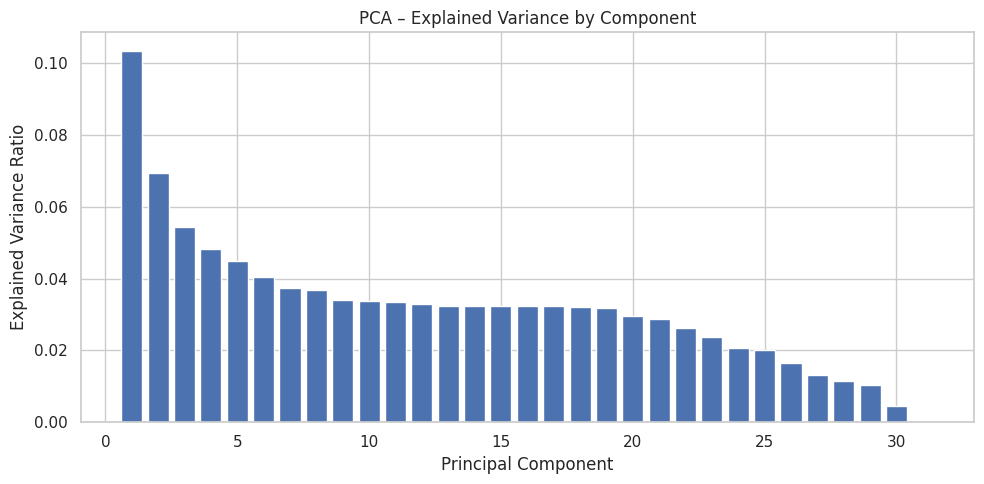

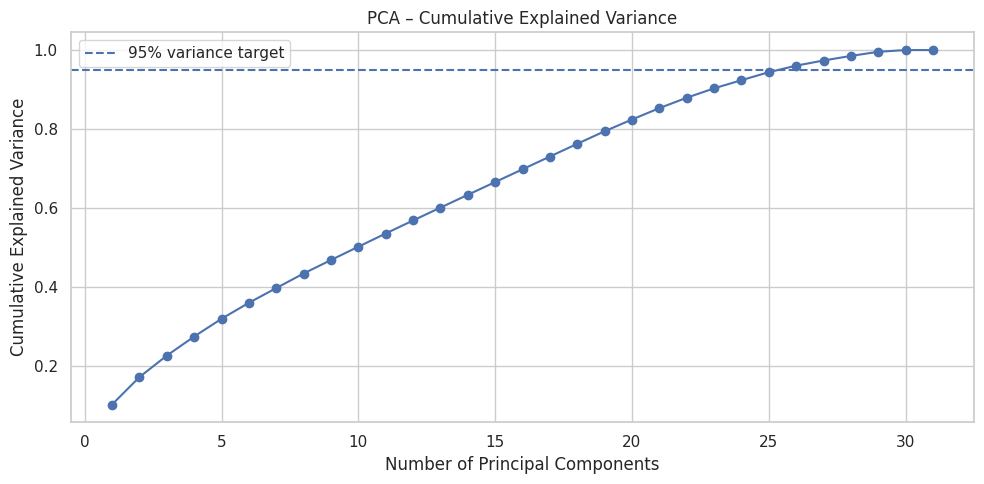

In [10]:
plt.figure(figsize=(10, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA – Explained Variance by Component")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(0.95, linestyle="--", label="95% variance target")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA – Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Creating the Reduced PCA Dataset

After identifying the number of components needed for the 95% variance target, I fit PCA again using that number of components. The output is a smaller dataset containing columns such as `PC1`, `PC2`, and so on.

These principal components replace the original selected features for the reduced representation. They are combinations of the original features, so they should not be interpreted as individual catalogue columns.

In [11]:
pca = PCA(n_components=n_components_95)
X_reduced = pca.fit_transform(X_standardized)

pca_columns = [f"PC{i+1}" for i in range(n_components_95)]
pca_results = pd.DataFrame(
    X_reduced,
    columns=pca_columns,
    index=df.index
)

print("Original PCA feature dimensions:", X_standardized.shape[1])
print("Reduced PCA dimensions:", X_reduced.shape[1])
print("Variance retained:", round(pca.explained_variance_ratio_.sum(), 4))

display(pca_results.head())

Original PCA feature dimensions: 31
Reduced PCA dimensions: 26
Variance retained: 0.9605


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26
0,0.287449,1.183809,0.869315,0.487860,2.681309,1.780464,1.397224,-0.612076,-0.715185,0.898772,0.495455,1.275939,-0.615330,-0.480562,-0.026010,-0.055437,1.772244e-14,-0.426501,-1.396897,2.090212,0.810571,-0.097387,0.891971,1.234338,0.815033,0.668910
1,-3.881177,-1.565899,-0.096408,-0.823849,-0.929713,1.007763,-0.460448,0.409297,-0.285223,0.175652,0.044777,0.161388,0.078025,0.096264,-0.005491,-0.017116,2.070726e-14,-0.052303,-0.036563,-0.146112,-0.074857,0.075327,0.572614,-0.615779,1.351306,0.275329
2,-2.523302,-0.820247,0.582020,-0.626487,-0.559720,0.813533,-0.158044,0.090706,-0.202342,-0.114618,-0.069792,-0.077887,-0.056799,0.003514,0.046353,-0.005178,-1.819279e-14,0.004589,-0.209395,-0.062670,-0.887311,-0.394593,-0.402394,0.802900,-1.097261,-0.093298
3,-1.483625,-0.242936,0.990140,-0.550357,-0.338235,0.485357,0.269712,-0.321640,0.210072,-0.164212,-0.053962,-0.188455,0.003257,-0.049606,-0.000392,0.010251,-9.078009e-15,0.067460,0.106438,-0.174022,-0.127336,-0.253155,-0.120326,0.666465,-0.656558,0.026174
4,-2.756426,-0.879071,0.419493,-0.657490,-0.561983,0.630479,0.047087,0.054198,0.059254,-0.031619,-0.026555,-0.070208,0.034698,-0.002258,-0.016187,0.001489,7.628569e-15,0.024308,0.119824,-0.144872,-0.170998,-0.163948,-0.135163,0.815367,-1.156337,-0.224392


## 11. Two-Dimensional PCA Projection

I also create a separate PCA projection with **two components** so the data can be viewed in a 2D scatter plot. Each point represents one Netflix title, positioned using its values on the first two principal components.

**Why use a 2D scatter plot?** It gives a simple visual overview of how titles are distributed in the reduced feature space and whether any broad groupings are visible. This 2D projection is mainly for visual inspection; it may not retain as much variance as the reduced PCA dataset selected using the 95% target.

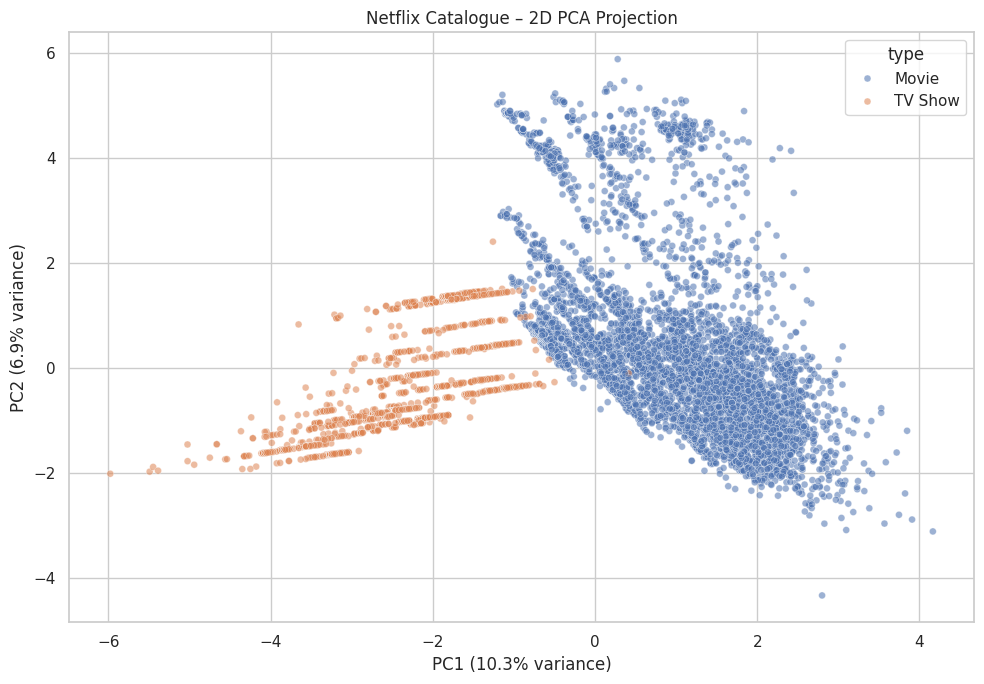

In [12]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_standardized)

pca_2d_df = pd.DataFrame(
    X_2d,
    columns=["PC1", "PC2"],
    index=df.index
)
pca_2d_df["type"] = df["type"].values

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_2d_df,
    x="PC1",
    y="PC2",
    hue="type",
    alpha=0.55,
    s=25
)
plt.title("Netflix Catalogue – 2D PCA Projection")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()

## 12. Exporting PCA Results

I save two output files:

- `netflix_pca_results.csv`: the reduced PCA dataset using the number of components selected from the explained-variance analysis.
- `netflix_pca_2d_visualization.csv`: the two-component projection prepared for 2D visualisation.

Saving these files makes the PCA results available for later analysis or dashboard work without having to repeat the full PCA process.

In [13]:
output_dir = Path("Dataset")
output_dir.mkdir(exist_ok=True)

pca_results.to_csv(output_dir / "netflix_pca_results.csv", index=False)
pca_2d_df.to_csv(output_dir / "netflix_pca_2d_visualization.csv", index=False)

print("Saved PCA outputs:")
print(output_dir / "netflix_pca_results.csv")
print(output_dir / "netflix_pca_2d_visualization.csv")

Saved PCA outputs:
Dataset/netflix_pca_results.csv
Dataset/netflix_pca_2d_visualization.csv


## 13. Week 7 – Short Report

In Week 7, I prepared a numerical feature matrix from selected Netflix catalogue attributes. I used One-Hot Encoding for content type and rating, and Multi-Hot Encoding for genres because a title can have more than one genre. I then reviewed correlations, removed one feature from highly correlated pairs using a 0.95 threshold, standardized the selected features, and applied PCA.

The explained-variance charts helped me decide how many principal components were needed to retain the target amount of variance. I also created a separate two-component projection for visual inspection and exported both PCA result files.

This analysis reduces the number of catalogue features while keeping as much of their variation as possible. Since the dataset describes Netflix titles rather than individual viewing records, the results show catalogue patterns and should not be treated as direct evidence of users' viewing habits.

In [14]:
print("WEEK 7 SUMMARY")
print("----------------")
print("Number of input features:", X_standardized.shape[1])
print("Number of components selected:", n_components_95)
print("Variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("Highly correlated pairs found:", len(high_corr_pairs))
print("PCA results exported successfully.")

WEEK 7 SUMMARY
----------------
Number of input features: 31
Number of components selected: 26
Variance retained: 0.9605
Highly correlated pairs found: 1
PCA results exported successfully.
